In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Colab: install ultralytics
%pip -q install ultralytics opencv-python

import os
import numpy as np
import cv2
from ultralytics import YOLO
from google.colab.patches import cv2_imshow


In [ ]:
# TODO: change these to your actual paths in Google Drive
WEIGHTS_PATH = "/content/drive/MyDrive/77_percent_F1_score_150e.pt"
IMAGE_PATH   = "/content/drive/MyDrive/YOLO_solo/raw_image/yuniklo.jpeg"

assert os.path.exists(WEIGHTS_PATH), f"Weights not found: {WEIGHTS_PATH}"
assert os.path.exists(IMAGE_PATH),   f"Image not found:   {IMAGE_PATH}"

model = YOLO(WEIGHTS_PATH)
print("Loaded model. Classes:", model.names)


Loaded model. Classes: {0: '0', 1: '1', 2: '2', 3: '3', 4: '4', 5: '5', 6: '6', 7: '7', 8: '8', 9: '9', 10: 'a-kara', 11: 'adeg-adeg', 12: 'ba', 13: 'ba-kembang', 14: 'bisah-h-', 15: 'ca', 16: 'cecek-ng-', 17: 'da', 18: 'da-madu', 19: 'e-kara', 20: 'end', 21: 'ga', 22: 'ga-gara', 23: 'gantungan-ba', 24: 'gantungan-ca', 25: 'gantungan-da', 26: 'gantungan-ga', 27: 'gantungan-ha', 28: 'gantungan-ja', 29: 'gantungan-ka', 30: 'gantungan-la', 31: 'gantungan-ma', 32: 'gantungan-na', 33: 'gantungan-nya', 34: 'gantungan-pa', 35: 'gantungan-ra', 36: 'gantungan-sa', 37: 'gantungan-ta', 38: 'gantungan-wa', 39: 'gantungan-ya', 40: 'ha', 41: 'i-kara', 42: 'ja', 43: 'ja-jera', 44: 'ka', 45: 'la', 46: 'le-lenga', 47: 'ma', 48: 'na', 49: 'na-rambat', 50: 'nga', 51: 'nya', 52: 'o-kara', 53: 'pa', 54: 'pa-kapal', 55: 'pepet', 56: 'ra', 57: 'ra-repa', 58: 'sa', 59: 'sa-saga', 60: 'sa-sapa', 61: 'suku', 62: 'surang-r-', 63: 'ta', 64: 'ta-latik', 65: 'ta-tawa', 66: 'taleng', 67: 'tedong', 68: 'u-kara', 69: 

In [ ]:
results = model(IMAGE_PATH, conf=0.25)[0]   # take first (and only) result
boxes   = results.boxes
img     = results.orig_img.copy()
H, W    = img.shape[:2]

if boxes is None or len(boxes) == 0:
    print("No detections.")
else:
    # get data
    xywhn   = boxes.xywhn.cpu().numpy()            # normalized (cx, cy, w, h)
    xyxy    = boxes.xyxy.cpu().numpy()             # pixel (x1, y1, x2, y2)
    classes = boxes.cls.cpu().numpy().astype(int)
    confs   = boxes.conf.cpu().numpy()

    print("Detections (class | center_norm | center_px | bbox_px | conf):")
    for (cx_n, cy_n, bw_n, bh_n), (x1, y1, x2, y2), cls_id, conf in \
            zip(xywhn, xyxy, classes, confs):

        # center in pixels (OpenCV coords, (0,0) at top-left)
        cx_px = int(cx_n * W)
        cy_px = int(cy_n * H)

        print(
            f"{cls_id} | "
            f"({cx_n:.4f}, {cy_n:.4f}) | "
            f"({cx_px}, {cy_px}) | "
            f"({int(x1)}, {int(y1)}, {int(x2)}, {int(y2)}) | "
            f"{conf:.3f}"
        )

        # draw bbox
        x1_i, y1_i, x2_i, y2_i = map(int, [x1, y1, x2, y2])
        cv2.rectangle(img, (x1_i, y1_i), (x2_i, y2_i), (0, 255, 0), 2)

        # write (x,y) coordinate above bbox
        coord_text = f"({cx_px},{cy_px})"
        cv2.putText(
            img,
            coord_text,
            (x1_i, max(0, y1_i - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            1,
            cv2.LINE_AA
        )


image 1/1 /content/drive/MyDrive/YOLO_solo/raw_image/yuniklo.jpeg: 640x288 1 end, 1 gantungan-la, 1 ka, 1 na, 1 suku, 1 surang-r-, 1 taleng, 1 tedong, 1 ulu, 2 yas, 379.8ms
Speed: 3.6ms preprocess, 379.8ms inference, 4.1ms postprocess per image at shape (1, 3, 640, 288)
Detections (class | center_norm | center_px | bbox_px | conf):
44 | (0.5387, 0.2509) | (387, 401) | (345, 374, 428, 428) | 0.864
69 | (0.3631, 0.2247) | (261, 359) | (236, 334, 285, 384) | 0.861
71 | (0.2522, 0.2588) | (181, 414) | (143, 386, 219, 441) | 0.860
20 | (0.7191, 0.2563) | (517, 410) | (488, 362, 545, 458) | 0.856
48 | (0.3594, 0.2570) | (258, 411) | (226, 384, 290, 438) | 0.855
66 | (0.4434, 0.2707) | (318, 433) | (295, 379, 342, 486) | 0.821
67 | (0.6364, 0.2488) | (457, 398) | (431, 369, 484, 426) | 0.799
61 | (0.2825, 0.3015) | (203, 482) | (185, 442, 220, 522) | 0.793
30 | (0.5469, 0.2846) | (393, 455) | (355, 429, 431, 481) | 0.703
71 | (0.0502, 0.2624) | (36, 419) | (1, 391, 71, 448) | 0.524
62 | (0.7

In [ ]:
# 7) OPTIONAL: draw coordinate grid & axis numbers (like math graph)
if boxes is not None and len(boxes) > 0:
    step = 50

    GRID_COLOR = (0, 255, 255)   # cyan (B, G, R)
    TEXT_COLOR = (0, 255, 255)

    # vertical grid lines + X labels
    for x in range(0, W, step):
        cv2.line(img, (x, 0), (x, H), GRID_COLOR, 1)
        cv2.putText(
            img, str(x), (x + 2, 15),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5,
            TEXT_COLOR, 1, cv2.LINE_AA
        )

    # horizontal grid lines + Y labels
    for y in range(0, H, step):
        cv2.line(img, (0, y), (W, y), GRID_COLOR, 1)
        cv2.putText(
            img, str(y), (2, y + 15),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5,
            TEXT_COLOR, 1, cv2.LINE_AA
        )

          # bounding boxes (GREEN)
    cv2.rectangle(img, (x1_i, y1_i), (x2_i, y2_i), (0, 255, 0), 2)
    cv2.putText(
        img, coord_text, (x1_i, max(0, y1_i - 10)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.5,
        (0, 255, 0), 1, cv2.LINE_AA
    )


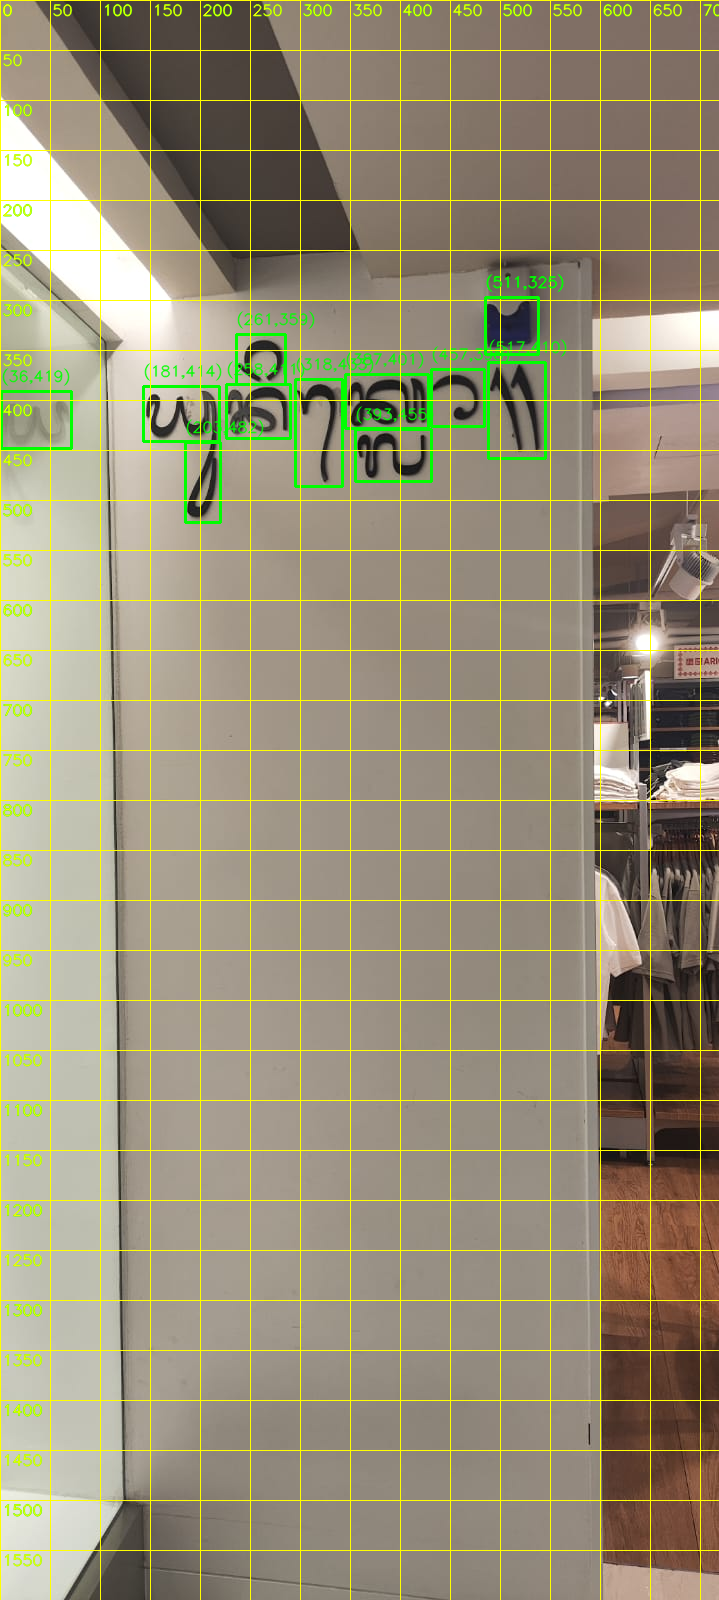

In [ ]:
# 8) Show final image
cv2_imshow(img)